# Modul 9 — Analisis Survival (Kaplan–Meier & Cox)
**Pertanyaan:** berapa lama komponen kritis bertahan, apakah umur berbeda antar jenis, dan apakah beban kerja atau lingkungan mempercepat kegagalan?

Dua kekhasan data kita:
- **Tersensor kanan:** beberapa komponen belum gagal saat pengamatan selesai (kita hanya tahu umurnya *lebih dari* itu).
- **Left truncation (delayed entry):** komponen sudah berumur `Umur_Awal_Hari` saat mulai diamati. Komponen yang gagal sebelum pengamatan dimulai tidak pernah masuk data, jadi kita hanya boleh membandingkan komponen dengan yang *sedang berisiko pada umur yang sama*.

Kita tulis **Kaplan–Meier**, **uji log-rank**, dan **model Cox stratified** sendiri dengan numpy/scipy.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
k = pd.read_excel(XLSX, sheet_name="Komponen_Kritis")
k["masuk"] = k.Umur_Awal_Hari.astype(float)
k["keluar"] = k.Umur_Awal_Hari + k.Durasi_Pengamatan_Hari
k["event"] = k["Gagal_1_Sensor_0"].astype(int)
print(k[["Jenis", "masuk", "keluar", "event", "Beban_Rata2_Persen", "Kelas_Lingkungan"]].head(8).round(1).to_string(index=False))
print(f"\nn={len(k)}, kegagalan={k.event.sum()}, tersensor={(1-k.event).sum()}")
print(k.groupby("Jenis").agg(n=("event", "size"), gagal=("event", "sum")).T)

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx
 Jenis  masuk  keluar  event  Beban_Rata2_Persen Kelas_Lingkungan
Tuyere   35.0   308.0      0                88.7           Sedang
Tuyere   80.0   250.6      1                82.9           Rendah
Tuyere  116.0   207.1      1                85.0           Tinggi
Tuyere  110.0   282.8      1                91.4           Rendah
Tuyere   63.0   129.8      1                80.1           Tinggi
Tuyere   29.0    93.7      1                94.5           Tinggi
Tuyere   97.0   147.0      1                93.5           Rendah
Tuyere   16.0   130.3      1                85.3           Sedang

n=44, kegagalan=35, tersensor=9
Jenis  Blower SO2  Demister  Kompresor Udara  Rectifier  Tuyere  Waste Heat Boiler Tube
n               6         6                6          6      12                       8
gagal           3         3                6          4      11                       8


## 1. Kaplan–Meier dengan delayed entry
Pada tiap waktu kegagalan *t*, **risk set** = komponen yang `masuk < t ≤ keluar`. Peluang bertahan:
`S(t) = Π (1 − d_j / n_j)`. Interval kepercayaan memakai transformasi **log-log** dan galat Greenwood.

In [ ]:
def kaplan_meier(masuk, keluar, event):
    masuk, keluar, event = map(np.asarray, (masuk, keluar, event))
    waktu = np.unique(keluar[event == 1]); S = 1.0; gw = 0.0; rows = []
    for t in waktu:
        n = ((masuk < t) & (keluar >= t)).sum(); d = ((keluar == t) & (event == 1)).sum()
        if n == 0: continue
        S *= 1 - d / n
        gw += d / (n * (n - d)) if n > d else np.inf
        rows.append((t, n, d, S, gw))
    df = pd.DataFrame(rows, columns=["t", "n_risiko", "d", "S", "gw"])
    with np.errstate(all="ignore"):
        se_ll = np.sqrt(df.gw) / np.abs(np.log(df.S))
        df["lo"] = df.S ** np.exp(1.96 * se_ll); df["hi"] = df.S ** np.exp(-1.96 * se_ll)
    return df

def median_surv(km):
    below = km[km.S <= 0.5]; return below.t.iloc[0] if len(below) else np.nan

km_all = kaplan_meier(k.masuk, k.keluar, k.event)
print(km_all.head(8).round(3).to_string(index=False))
print(f"\nMediana umur (KM, semua komponen): {median_surv(km_all):.0f} hari")

    t  n_risiko  d     S    gw    lo    hi
 56.8        13  1 0.923 0.006 0.566 0.989
 68.9        19  1 0.874 0.009 0.577 0.968
 72.5        21  1 0.833 0.012 0.558 0.944
 76.3        23  1 0.797 0.014 0.536 0.920
 82.1        27  1 0.767 0.015 0.518 0.899
 83.7        26  1 0.738 0.017 0.497 0.876
 93.7        30  1 0.713 0.018 0.481 0.855
107.9        31  1 0.690 0.019 0.465 0.836

Mediana umur (KM, semua komponen): 162 hari


**Perhatian:** pada umur sangat muda, risk set kecil (komponen baru masuk berangsur-angsur), sehingga estimasi S(t) di sana tidak stabil. Lihat kolom `n_risiko` sebelum mempercayai suatu titik.

## 2. Perbandingan antar jenis komponen

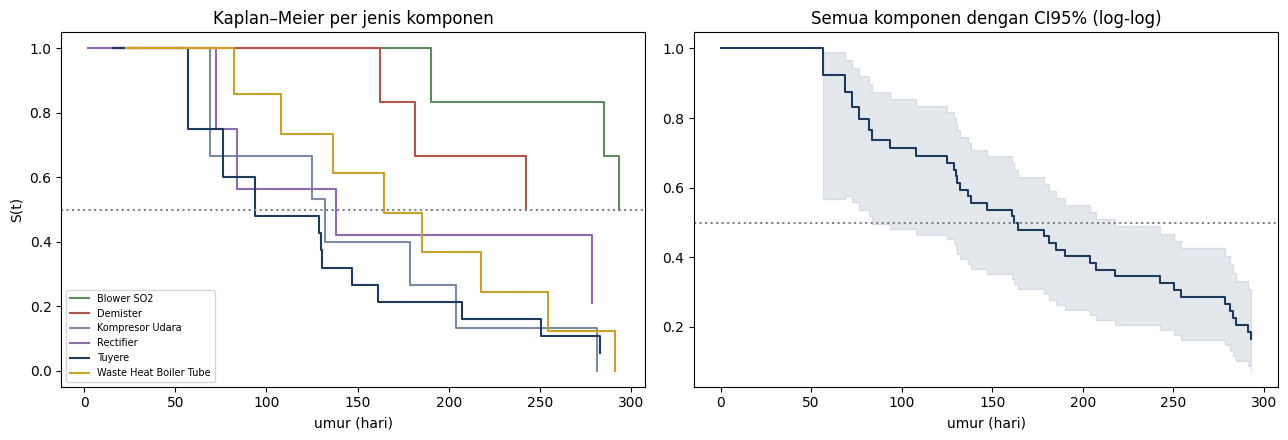

Mediana umur per jenis (hari; NaN = belum mencapai 50% gagal):
Blower SO2                293.0
Demister                  243.0
Kompresor Udara           132.0
Rectifier                 138.0
Tuyere                     94.0
Waste Heat Boiler Tube    164.0
dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
warna = {"Tuyere": "#1F3A5F", "Waste Heat Boiler Tube": "#C9A227", "Kompresor Udara": "#7A8CA3", "Blower SO2": "#5E8C61", "Demister": "#B5544A", "Rectifier": "#8E6BB0"}
med = {}
for jenis, g in k.groupby("Jenis"):
    km = kaplan_meier(g.masuk, g.keluar, g.event); med[jenis] = median_surv(km)
    t = np.r_[km.t.min() * 0 + g.masuk.min(), km.t.values]; S = np.r_[1.0, km.S.values]
    ax[0].step(t, S, where="post", label=jenis, color=warna[jenis])
ax[0].set_xlabel("umur (hari)"); ax[0].set_ylabel("S(t)"); ax[0].set_title("Kaplan–Meier per jenis komponen"); ax[0].legend(fontsize=7); ax[0].axhline(.5, color="gray", ls=":")
t = np.r_[0, km_all.t.values]; S = np.r_[1.0, km_all.S.values]
ax[1].step(t, S, where="post", color="#1F3A5F"); ax[1].fill_between(km_all.t, km_all.lo, km_all.hi, step="post", alpha=.2, color="#7A8CA3")
ax[1].set_title("Semua komponen dengan CI95% (log-log)"); ax[1].set_xlabel("umur (hari)"); ax[1].axhline(.5, color="gray", ls=":")
plt.tight_layout(); plt.show()
print("Mediana umur per jenis (hari; NaN = belum mencapai 50% gagal):"); print(pd.Series(med).round(0))

## 3. Uji log-rank (dua kelompok, dengan delayed entry)
H0: kedua kelompok punya fungsi hazard sama. Pada tiap waktu kegagalan dihitung kegagalan teramati vs harapan jika hazard sama; dijumlahkan menjadi statistik χ² (db = 1).

In [ ]:
def logrank(masuk, keluar, event, grup):
    masuk, keluar, event, grup = map(np.asarray, (masuk, keluar, event, grup)); O_E = 0.0; V = 0.0
    for t in np.unique(keluar[event == 1]):
        berisiko = (masuk < t) & (keluar >= t); n = berisiko.sum(); n1 = (berisiko & (grup == 1)).sum()
        d = ((keluar == t) & (event == 1)).sum(); d1 = ((keluar == t) & (event == 1) & (grup == 1)).sum()
        if n < 2: continue
        O_E += d1 - d * n1 / n; V += d * (n1 / n) * (1 - n1 / n) * (n - d) / (n - 1)
    chi = O_E**2 / V; return chi, stats.chi2.sf(chi, 1)

kk = k[k.Jenis.isin(["Tuyere", "Waste Heat Boiler Tube"])]
chi, p = logrank(kk.masuk, kk.keluar, kk.event, (kk.Jenis == "Tuyere").astype(int)); print(f"Tuyere vs Waste Heat Boiler Tube: chi²={chi:.2f}, p={p:.3f}")
kk = k[k.Kelas_Lingkungan.isin(["Rendah", "Tinggi"])]
chi, p = logrank(kk.masuk, kk.keluar, kk.event, (kk.Kelas_Lingkungan == "Tinggi").astype(int)); print(f"Lingkungan Tinggi vs Rendah     : chi²={chi:.2f}, p={p:.3f}")

Tuyere vs Waste Heat Boiler Tube: chi²=0.16, p=0.689
Lingkungan Tinggi vs Rendah     : chi²=0.09, p=0.759


## 4. Model Cox stratified (proportional hazards)
`h(t | x) = h₀,jenis(t) · exp(β·x)`. **Stratified menurut jenis** artinya tiap jenis punya baseline hazard sendiri (karena umur tiap jenis berbeda jauh), sedangkan efek kovariat (beban, lingkungan) dibagi bersama. Dengan hanya 35 kegagalan, kita membatasi jumlah kovariat (≈ 10 kegagalan per parameter).

Log partial likelihood dengan delayed entry: pada tiap kegagalan *i* di strata *s*, risk set = komponen dalam strata yang sama dengan `masuk < t_i ≤ keluar`.

In [ ]:
k["beban10"] = (k.Beban_Rata2_Persen - k.Beban_Rata2_Persen.mean()) / 10          # per 10 poin persen
k["env_sedang"] = (k.Kelas_Lingkungan == "Sedang").astype(float); k["env_tinggi"] = (k.Kelas_Lingkungan == "Tinggi").astype(float)
COVS = ["beban10", "env_sedang", "env_tinggi"]

def cox_terms(beta, df, covs):
    X = df[covs].values; eta = X @ beta; ll = 0.0; grad = np.zeros(len(beta)); H = np.zeros((len(beta), len(beta)))
    for _, g in df.groupby("Jenis"):
        Xg = g[covs].values; eg = np.exp(Xg @ beta); m, e_, ev = g.masuk.values, g.keluar.values, g.event.values
        for i in np.where(ev == 1)[0]:
            r = (m < e_[i]) & (e_ >= e_[i]); w = eg[r]; sw = w.sum(); xr = Xg[r]
            xbar = (w[:, None] * xr).sum(0) / sw
            ll += Xg[i] @ beta - np.log(sw); grad += Xg[i] - xbar
            H -= (xr.T * w) @ xr / sw - np.outer(xbar, xbar)
    return ll, grad, H

fit = optimize.minimize(lambda b: -cox_terms(b, k, COVS)[0], np.zeros(len(COVS)), jac=lambda b: -cox_terms(b, k, COVS)[1], method="BFGS")
beta = fit.x; _, _, Hess = cox_terms(beta, k, COVS); cov = np.linalg.inv(-Hess); se = np.sqrt(np.diag(cov))
res = pd.DataFrame({"koef": beta, "HR": np.exp(beta), "HR_lo": np.exp(beta - 1.96 * se), "HR_hi": np.exp(beta + 1.96 * se),
                    "p": 2 * stats.norm.sf(np.abs(beta / se))}, index=["beban (per +10 poin)", "lingkungan Sedang (vs Rendah)", "lingkungan Tinggi (vs Rendah)"])
print(res.round(3))
ll1 = cox_terms(beta, k, COVS)[0]; ll0 = cox_terms(np.zeros(len(COVS)), k, COVS)[0]
print(f"\nUji rasio likelihood model vs tanpa kovariat: chi²={2*(ll1-ll0):.2f}, db={len(COVS)}, p={stats.chi2.sf(2*(ll1-ll0), len(COVS)):.3f}")

                                koef     HR  HR_lo  HR_hi      p
beban (per +10 poin)          -0.209  0.812  0.371  1.775  0.601
lingkungan Sedang (vs Rendah) -0.127  0.881  0.296  2.620  0.819
lingkungan Tinggi (vs Rendah)  0.231  1.260  0.388  4.086  0.701

Uji rasio likelihood model vs tanpa kovariat: chi²=0.70, db=3, p=0.874


**Membaca HR (hazard ratio):** HR = 1,3 berarti laju kegagalan 30% lebih tinggi untuk kenaikan 1 satuan kovariat (pada umur yang sama). Jika CI95% mencakup 1, efeknya tidak terbukti.

**Catatan pembelajaran:** kolom beban dan lingkungan pada data simulasi ini dibuat **independen** dari umur gagal. Hasil yang benar adalah *tidak ada efek signifikan*. Model yang baik tidak mengarang efek ketika data tidak mendukungnya. Pada data pabrik nyata, kovariat seperti suhu operasi atau jam start-stop barulah diuji sungguhan.

## 5. Memeriksa asumsi proportional hazards (residu Schoenfeld)
Jika efek kovariat konstan sepanjang umur, residu Schoenfeld (kovariat komponen yang gagal dikurangi rata-rata tertimbang di risk set) tidak berkorelasi dengan waktu.

In [ ]:
rows = []
for j, c in enumerate(COVS):
    tt, rr = [], []
    for _, g in k.groupby("Jenis"):
        Xg = g[COVS].values; eg = np.exp(Xg @ beta); m, e_, ev = g.masuk.values, g.keluar.values, g.event.values
        for i in np.where(ev == 1)[0]:
            r = (m < e_[i]) & (e_ >= e_[i]); w = eg[r]; xbar = (w * Xg[r, j]).sum() / w.sum()
            tt.append(e_[i]); rr.append(Xg[i, j] - xbar)
    rho, pv = stats.spearmanr(tt, rr); rows.append(dict(kovariat=c, rho_waktu=rho, p=pv))
print(pd.DataFrame(rows).round(3).to_string(index=False)); print("(p kecil = efek berubah menurut umur = asumsi PH diragukan)")

  kovariat  rho_waktu     p
   beban10      0.075 0.670
env_sedang     -0.272 0.114
env_tinggi      0.307 0.073
(p kecil = efek berubah menurut umur = asumsi PH diragukan)


## 6. Hubungan dengan Weibull (Modul 4)
Mediana umur KM seharusnya selaras dengan mediana model Weibull `η·(ln 2)^(1/β)` dari Modul 4, hanya saja KM tidak berasumsi bentuk distribusi.

In [ ]:
weib = {"Blower SO2": (4.216, 358.4), "Demister": (1.419, 414.0), "Kompresor Udara": (2.289, 175.0), "Rectifier": (0.678, 145.8),
        "Tuyere": (1.269, 127.9), "Waste Heat Boiler Tube": (2.486, 190.6)}
bandingkan = pd.DataFrame({"mediana_KM": pd.Series(med), "mediana_Weibull": {j: e * np.log(2) ** (1 / b) for j, (b, e) in weib.items()}})
print(bandingkan.round(0))
print("\n(Hati-hati: KM bisa NaN bila kurang dari 50% komponen gagal dalam jendela pengamatan; Weibull mengekstrapolasi.)")

                        mediana_KM  mediana_Weibull
Blower SO2                   293.0            329.0
Demister                     243.0            320.0
Kompresor Udara              132.0            149.0
Rectifier                    138.0             85.0
Tuyere                        94.0             96.0
Waste Heat Boiler Tube       164.0            164.0

(Hati-hati: KM bisa NaN bila kurang dari 50% komponen gagal dalam jendela pengamatan; Weibull mengekstrapolasi.)


**Kesimpulan modul 9.**
*   44 komponen, 35 gagal. Median umur 162 hari: Blower SO2 293, demister 243, boiler tube 164, rectifier 138, kompresor 132, tuyere 94.
*   Tidak ada efek signifikan dari beban atau lingkungan (uji rasio likelihood p = 0,874), dan tuyere vs boiler tube tidak berbeda (p = 0,689). Sampel kecil, jadi ini bukan bukti bahwa efeknya tidak ada.
*   Weibull dan Kaplan-Meier berbeda untuk rectifier (85 vs 138 hari), sehingga model Weibull kurang cocok untuk komponen itu.



